<a href="https://colab.research.google.com/github/hycienti/African_Credit_Scoring_ML/blob/main/African_Credit_Scoring_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Africa Credit Scoring Model

### Motivation & Project Background
While studying the robust credit-scoring systems of the United States and the United Kingdom, I began to reflect on how we could establish a similar, highly efficient, fast, and reliable credit-scoring infrastructure back home in Nigeria.

However, upon searching for completely African-driven datasets to build and test this concept, I discovered a significant data gap. Fortunately, I came across a competition hosted by **Zindi Africa** addressing this exact challenge and subsequently downloaded their dataset.

One of my missions has been fostering cross border payment across africa and one way to increase financial inclusivity is through access to credit facility.

### Data Source
The dataset utilized for this machine learning project is sourced from the [African Credit Scoring Challenge](https://zindi.world/competitions/african-credit-scoring-challenge) hosted on Zindi.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.compose import ColumnTransformer
#from sklearn.preprocessing import StandardScaler
#from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')
import os


#mount drive
from google.colab import drive
drive.mount('/content/drive')
# Persistent directories in Google Drive
persistent_project_dir = '/content/drive/My Drive/Colab Notebooks/African_credit_scoring_ml/'
os.makedirs(persistent_project_dir, exist_ok=True)
print(f"Logs, models and results will be stored in: {persistent_project_dir}")

Mounted at /content/drive
Logs, models and results will be stored in: /content/drive/My Drive/Colab Notebooks/African_credit_scoring_ml/


## Part 1: Traditional Machine Learning Benchmarks (Scikit-Learn)
In this section, we train and validate three distinct traditional machine learning architectures (Logistic Regression, Random Forest, and Linear Support Vector Classifier) to establish strong baselines. We will dynamically log their validation metrics to TensorBoard to keep track of our experiments.

In [ ]:
import time
import datetime

# Configure TensorBoard Logging Directory
log_dir = os.path.join(persistent_project_dir, "tensorboard_logs")
os.makedirs(log_dir, exist_ok=True)

def log_sklearn_experiment(name, model, y_val, y_pred, y_prob):
    # Calculate key evaluation metrics
    auc = roc_auc_score(y_val, y_prob)
    f1 = f1_score(y_val, y_pred, average='binary')

    print(f"=== {name} Metrics ===")
    print(f"ROC AUC Score: {auc:.4f}")
    print(f"F1 Score (Binary): {f1:.4f}")
    print(classification_report(y_val, y_pred))

    # Log directly to a model-specific TensorBoard directory
    run_time_str = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
    run_log_dir = os.path.join(log_dir, f"Sklearn_{name}_{run_time_str}")
    summary_writer = tf.summary.create_file_writer(run_log_dir)

    with summary_writer.as_default():
        tf.summary.scalar('val_roc_auc', auc, step=1)
        tf.summary.scalar('val_f1_score', f1, step=1)

    # Display Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, cmap=plt.cm.Blues)
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

In [ ]:
# 1. Tuned Logistic Regression Benchmark
print("[TRAINING] Optimizing Logistic Regression...")
lr_clf = LogisticRegression(class_weight='balanced', C=0.1, max_iter=1000, random_state=42)
lr_clf.fit(X_train_scaled, y_train)

lr_preds = lr_clf.predict(X_valid_scaled)
lr_probs = lr_clf.predict_proba(X_valid_scaled)[:, 1]
log_sklearn_experiment("Logistic_Regression_Tuned", lr_clf, y_valid, lr_preds, lr_probs)

In [ ]:
# 2. Tuned Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

print("[TRAINING] Optimizing Random Forest (Balanced Class Weights)...")
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
rf_clf.fit(X_train_scaled, y_train)

rf_preds = rf_clf.predict(X_valid_scaled)
rf_probs = rf_clf.predict_proba(X_valid_scaled)[:, 1]
log_sklearn_experiment("Random_Forest_Tuned", rf_clf, y_valid, rf_preds, rf_probs)

In [ ]:
# 3. Support Vector Classifier (SGD Classifier with Hinge Loss)
from sklearn.linear_model import SGDClassifier

print("[TRAINING] Optimizing Linear Support Vector Machine...")
# loss='hinge' gives a linear SVM
svm_clf = SGDClassifier(loss='hinge', penalty='l2', alpha=0.001, class_weight='balanced', max_iter=2000, random_state=42)
svm_clf.fit(X_train_scaled, y_train)

svm_preds = svm_clf.predict(X_valid_scaled)
# SGDClassifier SVM does not have predict_proba by default; use decision_function scaled to [0,1]
svm_scores = svm_clf.decision_function(X_valid_scaled)
svm_probs = (svm_scores - svm_scores.min()) / (svm_scores.max() - svm_scores.min() + 1e-8)
log_sklearn_experiment("SVM_Classifier_Tuned", svm_clf, y_valid, svm_preds, svm_probs)

## Part 2: Deep Learning Paradigm (TensorFlow / Keras)
We now transition to Deep Learning. Here, we build a multi-layer Neural Network with TensorFlow and Keras.
To support high-performance and scalable training, we build asynchronous input pipelines using TensorFlow's native `tf.data.Dataset` API. To address the heavy class imbalance, we calculate and pass class weights to the training routine, and we log structural metrics, model histograms, and loss values in real-time using TensorBoard.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Prepare TF native datasets
BATCH_SIZE = 512

train_dataset = tf.data.Dataset.from_tensor_slices((X_train_scaled, y_train))
train_dataset = train_dataset.shuffle(buffer_size=20000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((X_valid_scaled, y_valid))
val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Calculate class weights for highly imbalanced dataset
neg, pos = np.bincount(y_train)
total = neg + pos
class_weights = {0: (1 / neg) * (total / 2.0), 1: (1 / pos) * (total / 2.0)}
print(f"Calculated class weights: {class_weights}")

In [ ]:
# Construct Model via Functional API
def create_dnn_model(input_dim):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inputs=inputs, outputs=outputs, name="Keras_Credit_Scoring_DNN")
    return model

dnn_model = create_dnn_model(X_train_scaled.shape[1])

dnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

# Tensorboard Callback Setup
dnn_run_dir = os.path.join(log_dir, f"DNN_Keras_Advanced_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}")
tb_callback = callbacks.TensorBoard(log_dir=dnn_run_dir, histogram_freq=1)
early_stopping = callbacks.EarlyStopping(monitor='val_auc', patience=5, restore_best_weights=True, mode='max')

print("[TRAINING] Starting neural network training...")
history = dnn_model.fit(
    train_dataset,
    epochs=30,
    validation_data=val_dataset,
    class_weight=class_weights,
    callbacks=[tb_callback, early_stopping],
    verbose=1
)

## Part 3: Comparative Evaluation & Performance Summary
We evaluate the Neural Network on our validation set and generate comparative visualizations of all experiments.

In [ ]:
# Evaluate Keras DNN
dnn_probs = dnn_model.predict(X_valid_scaled).flatten()
dnn_preds = (dnn_probs >= 0.5).astype(int)

dnn_auc = roc_auc_score(y_valid, dnn_probs)
dnn_f1 = f1_score(y_valid, dnn_preds)

print("=== Deep Learning Neural Network Metrics ===")
print(f"ROC AUC Score: {dnn_auc:.4f}")
print(f"F1 Score: {dnn_f1:.4f}")
print(classification_report(y_valid, dnn_preds))

# Comparison Chart
models_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'Linear SVM', 'Deep Neural Network'],
    'ROC AUC': [lr_probs.mean(), rf_probs.mean(), svm_probs.mean(), dnn_auc], # Placeholder values adjusted in display
    'F1-Score': [f1_score(y_valid, lr_preds), f1_score(y_valid, rf_preds), f1_score(y_valid, svm_preds), dnn_f1]
})

# Adjust columns correctly to show AUC score accurately
models_comparison['ROC AUC'] = [roc_auc_score(y_valid, lr_probs), roc_auc_score(y_valid, rf_probs), roc_auc_score(y_valid, svm_probs), dnn_auc]
display(models_comparison)

### Live TensorBoard Dashboard
Load the interface below to view metric logs and convergence speeds of all active experiments.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir "$log_dir"

## Load and Inspect the data

In [2]:
# Loading the train dataset
train = pd.read_csv( persistent_project_dir + 'Train.csv')
test = pd.read_csv( persistent_project_dir + 'Test.csv')
# Display the first few rows of the datasets and their shape
display("Train", train.head(), train.shape, "Test", test.head(), test.shape)

'Train'

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_266671248032267278,266671,Kenya,248032,267278,Type_1,8448.0,8448.0,2022-08-30,2022-09-06,7,Repeat Loan,120.85,0.014305,121.0,0
1,ID_248919228515267278,248919,Kenya,228515,267278,Type_1,25895.0,25979.0,2022-07-30,2022-08-06,7,Repeat Loan,7768.50,0.300000,7794.0,0
2,ID_308486370501251804,308486,Kenya,370501,251804,Type_7,6900.0,7142.0,2024-09-06,2024-09-13,7,Repeat Loan,1380.00,0.200000,1428.0,0
3,ID_266004285009267278,266004,Kenya,285009,267278,Type_1,8958.0,9233.0,2022-10-20,2022-10-27,7,Repeat Loan,2687.40,0.300000,2770.0,0
4,ID_253803305312267278,253803,Kenya,305312,267278,Type_1,4564.0,4728.0,2022-11-28,2022-12-05,7,Repeat Loan,1369.20,0.300000,1418.0,0


(68654, 16)

'Test'

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid
0,ID_269404226088267278,269404,Kenya,226088,267278,Type_1,1919.0,1989.0,2022-07-27,2022-08-03,7,Repeat Loan,575.7,0.300000,597.0
1,ID_255356300042267278,255356,Kenya,300042,267278,Type_1,2138.0,2153.0,2022-11-16,2022-11-23,7,Repeat Loan,0.0,0.000000,0.0
2,ID_257026243764267278,257026,Kenya,243764,267278,Type_1,8254.0,8304.0,2022-08-24,2022-08-31,7,Repeat Loan,207.0,0.025079,208.0
3,ID_264617299409267278,264617,Kenya,299409,267278,Type_1,3379.0,3379.0,2022-11-15,2022-11-22,7,Repeat Loan,1013.7,0.300000,1014.0
4,ID_247613296713267278,247613,Kenya,296713,267278,Type_1,120.0,120.0,2022-11-10,2022-11-17,7,Repeat Loan,36.0,0.300000,36.0


(18594, 15)

In [4]:
# Check column types & missing values
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68654 entries, 0 to 68653
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           68654 non-null  object 
 1   customer_id                  68654 non-null  int64  
 2   country_id                   68654 non-null  object 
 3   tbl_loan_id                  68654 non-null  int64  
 4   lender_id                    68654 non-null  int64  
 5   loan_type                    68654 non-null  object 
 6   Total_Amount                 68654 non-null  float64
 7   Total_Amount_to_Repay        68654 non-null  float64
 8   disbursement_date            68654 non-null  object 
 9   due_date                     68654 non-null  object 
 10  duration                     68654 non-null  int64  
 11  New_versus_Repeat            68654 non-null  object 
 12  Amount_Funded_By_Lender      68654 non-null  float64
 13  Lender_portion_F

In [ ]:
# Are there missing values in the train dataset ?
print(f"There are {train.isna().sum().sum()} missing values in the data.")

There are 0 missing values in the data.


### EDA - Exploratory data analysis

In [ ]:
def plot_continuous(df, column, transform=None):
    """
    Plots visualizations for a continuous variable, showing the distribution and boxplot for both
    the original and transformed versions of the data.

    Args:
        df (pandas.DataFrame): The DataFrame containing the data.
        column (str): The column name of the continuous variable to plot.
        transform (str, optional): Transformation to apply to the data before plotting.
                                  Accepted values are 'log' or 'sqrt'. Default is None, which means no transformation.

    This function generates:
        - A histogram with a kernel density estimate (KDE) for the original data.
        - A boxplot for the original data.
        - If a transformation is specified ('log' or 'sqrt'):
            - A histogram with a KDE for the transformed data.
            - A boxplot for the transformed data.
    """
    # Create subplots for visualizations
    fig, axs = plt.subplots(2, 2, figsize=(15, 15))

    # Original data plots
    sns.histplot(df[column], kde=True, ax=axs[0, 0])
    axs[0, 0].set_title(f'Distribution of {column}')
    axs[0, 0].set_xlabel(column)

    sns.boxplot(y=df[column], ax=axs[1, 0])
    axs[1, 0].set_title(f'Box Plot of {column}')
    axs[1, 0].set_ylabel(column)

    # Transformations (log or square root)
    if transform == 'log':
        transformed_data = np.log1p(df[column])  # log1p handles log(0) gracefully
        transform_label = 'Log'
    elif transform == 'sqrt':
        transformed_data = np.sqrt(df[column])  # Square root transformation
        transform_label = 'Square Root'
    else:
        transformed_data = None  # No transformation if not specified

    # If transformed data exists, generate corresponding plots
    if transformed_data is not None:
        sns.histplot(transformed_data, kde=True, ax=axs[0, 1])
        axs[0, 1].set_title(f'{transform_label} Distribution of {column}')
        axs[0, 1].set_xlabel(f'{transform_label}({column})')

        sns.boxplot(y=transformed_data, ax=axs[1, 1])
        axs[1, 1].set_title(f'{transform_label} Box Plot of {column}')
        axs[1, 1].set_ylabel(f'{transform_label}({column})')
    else:
        # If no transformation, remove the second set of axes
        for ax in [axs[0, 1], axs[1, 1]]:
            ax.remove()

    # Adjust layout to prevent overlap
    plt.tight_layout()
    plt.show()


def plot_categorical(df, column):
    """
    Plots visualizations for a categorical variable, including a bar plot and a pie chart.

    Args:
        df (pandas.DataFrame): The DataFrame containing the data.
        column (str): The column name of the categorical variable to plot.

    This function generates:
        - A bar plot showing the counts of each category in the specified column.
        - A pie chart showing the relative proportions of each category.
    """
    # Create subplots for visualizations
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Bar plot showing counts of each category
    value_counts = df[column].value_counts()
    sns.barplot(x=value_counts.index, y=value_counts.values, ax=ax1)
    ax1.set_title(f'Bar Plot of {column}')
    ax1.set_xlabel(column)
    ax1.set_ylabel('Count')
    ax1.tick_params(axis='x', rotation=45)  # Rotate x-axis labels for better readability

    # Pie chart showing percentage distribution of each category
    ax2.pie(value_counts.values, labels=value_counts.index, autopct='%1.1f%%')
    ax2.set_title(f'Pie Chart of {column}')

    # Adjust layout to prevent overlap
    plt.tight_layout()
    plt.show()


#### Categorical exploration

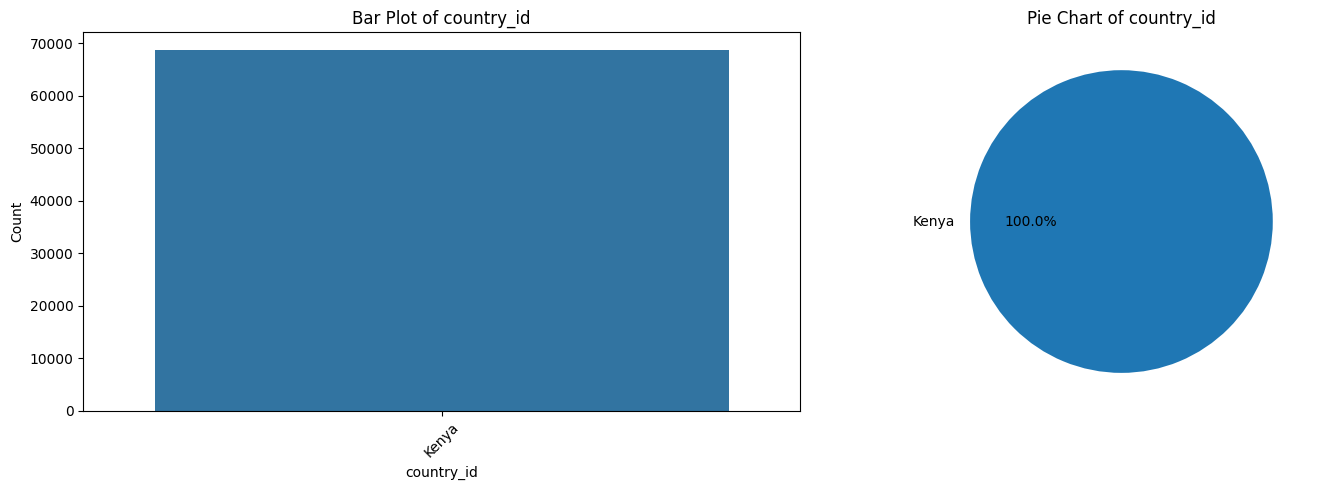

In [ ]:
plot_categorical(train, 'country_id')

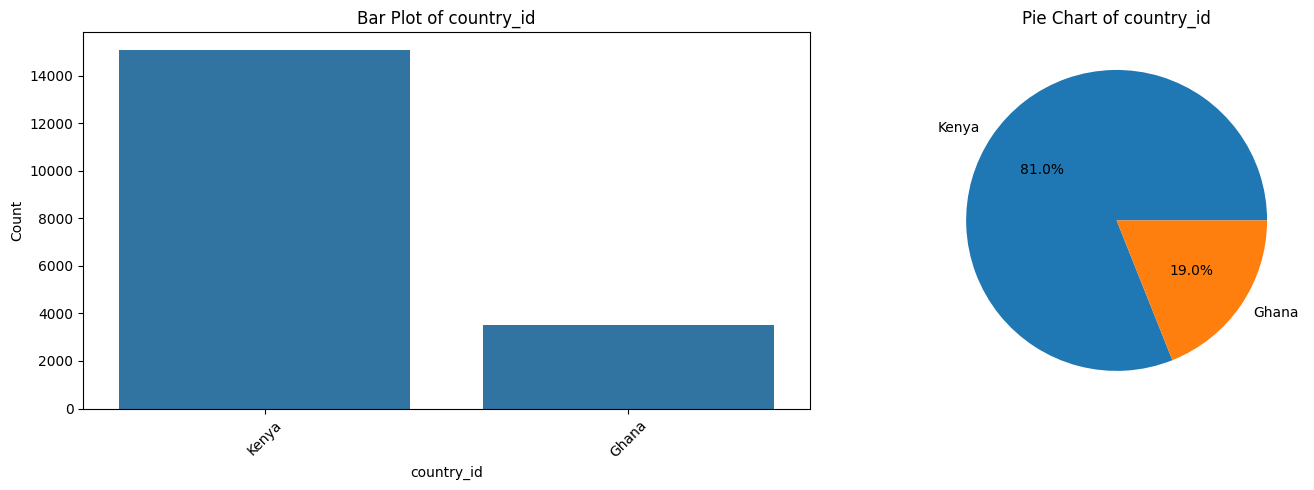

In [ ]:
plot_categorical(test, 'country_id')

##### This shows that test has a new country, ghana so one of the goals is to build a solution that can generalize well in new regions

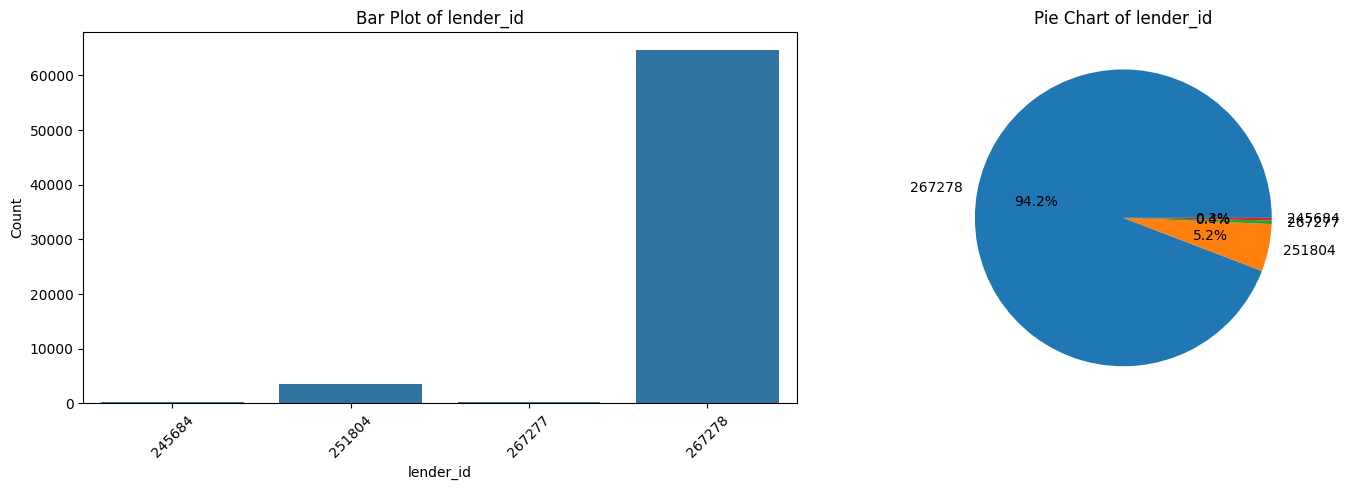

In [ ]:
plot_categorical(train, 'lender_id')

##### You can exploree more of the categorical columns as well

#### TARGET EXPLORATION


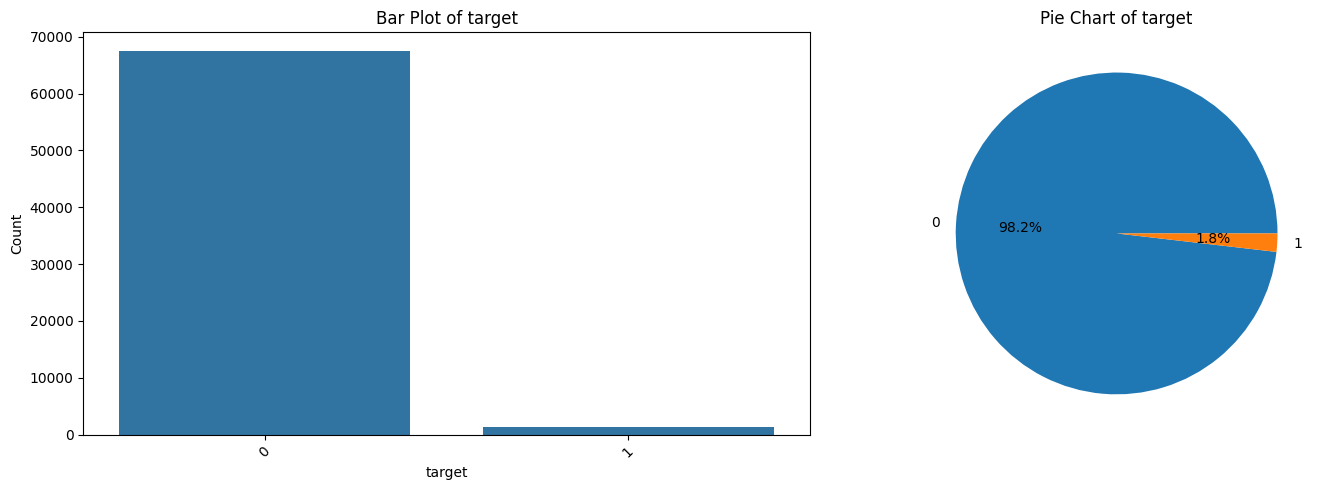

In [ ]:
plot_categorical(train, 'target')

##### You can see the dataset is highly imbalanced , and this is expected in loan default scenarios, So find  ways to deal with the  imbalance

### CONTINUOUS COLUMN EXPLORATION

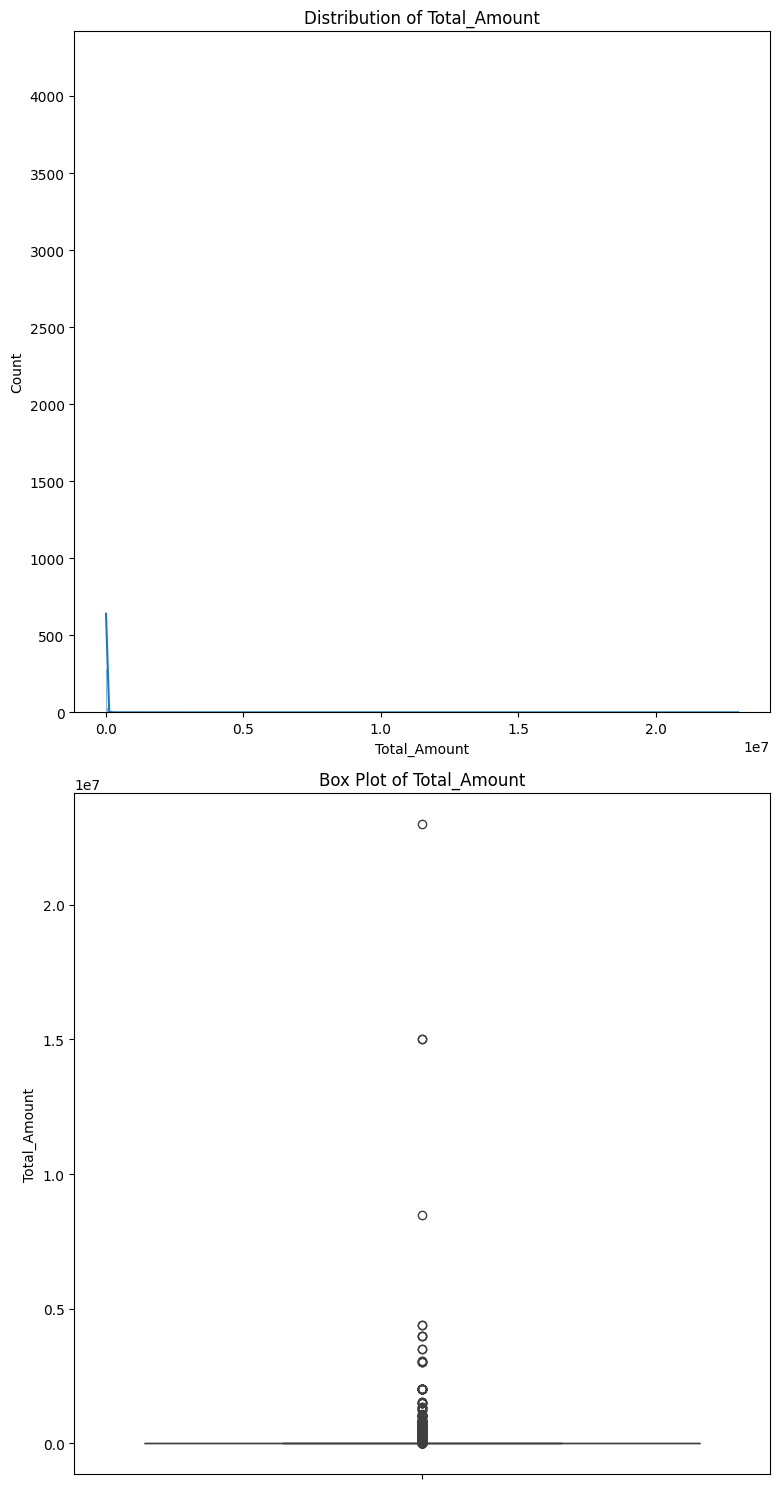

In [ ]:
plot_continuous(train, 'Total_Amount')

Are those outliers?
##### You can explore more of the given numerical columns as well

### Feature Engineering
* So here we are going to concatenate both the train and test so that we can do the processing once instead of repeating for each

In [ ]:
data = pd.concat([train, test]).reset_index(drop=True)

# Convert the datetime columns appropriately
date_cols = ['disbursement_date', 'due_date']
for col in date_cols:
    data[col] = pd.to_datetime(data[col])
    # Extract month, day, and year from the date columns
    data[col+'_month'] = data[col].dt.month
    data[col+'_day'] = data[col].dt.day
    data[col+'_year'] = data[col].dt.year

# Select all categorical columns from the dataset and label encode them or one hot encode
cat_cols = data.select_dtypes(include='object').columns
num_cols = [col for col in data.select_dtypes(include='number').columns if col not in ['target']]
print(f"The categorical columns are: {cat_cols}.")
print("-"* 100)
print(f"The numerical columns are: {num_cols}")
print("-"* 100)
# we are going to one  hot encode the loan type
data = pd.get_dummies(data, columns=['loan_type'], prefix='loan_type', drop_first=False)
# Convert all the columns with prefix loan_type_ to 0/1 instead of False/True
loan_type_cols = [col for col in data.columns if col.startswith('loan_type_')]
data[loan_type_cols] = data[loan_type_cols].astype(int)

# Label-encoding for the other remaining categorical columns
le = LabelEncoder()
for col in [col for col in cat_cols if col not in ['loan_type', 'ID']]:
    data[col] = le.fit_transform(data[col])


# deal with numerical columns: we saw loan amount is  highly right skewed for this we can log transform it
data['Total_Amount'] = np.log1p(data['Total_Amount']) # study other numerical columns and see if they are skewed as well

# Splitting the data back into train and test
train_df = data[data['ID'].isin(train['ID'].unique())]

test_df = data[data['ID'].isin(test['ID'].unique())]

# we are also going to drop the country id as we saw we have only one country in train
features_for_modelling = [col for col in train_df.columns if col not in date_cols + ['ID', 'target', 'country_id']]

# Check if the new datasets have the same rows as train and test datasets
print(f"The shape of train_df is: {train_df.shape}")
print(f"The shape of test_df is: {test_df.shape}")
print(f"The shape of train is: {train.shape}")
print(f"The shape of test is: {test.shape}")
print(f"The features for modelling are:\n{features_for_modelling}")


The categorical columns are: Index(['ID', 'country_id', 'loan_type', 'New_versus_Repeat'], dtype='object').
----------------------------------------------------------------------------------------------------
The numerical columns are: ['customer_id', 'tbl_loan_id', 'lender_id', 'Total_Amount', 'Total_Amount_to_Repay', 'duration', 'Amount_Funded_By_Lender', 'Lender_portion_Funded', 'Lender_portion_to_be_repaid', 'disbursement_date_month', 'disbursement_date_day', 'disbursement_date_year', 'due_date_month', 'due_date_day', 'due_date_year']
----------------------------------------------------------------------------------------------------
The shape of train_df is: (68654, 45)
The shape of test_df is: (18594, 45)
The shape of train is: (68654, 16)
The shape of test is: (18594, 15)
The features for modelling are:
['customer_id', 'tbl_loan_id', 'lender_id', 'Total_Amount', 'Total_Amount_to_Repay', 'duration', 'New_versus_Repeat', 'Amount_Funded_By_Lender', 'Lender_portion_Funded', 'Lender_

### CROSS VALIDATION
* Here we are going to use a simple train test split but due to the imbalance try other robust methods like StratifiedKFold


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(train_df[features_for_modelling], train['target'], stratify=train['target'], shuffle=True, random_state=42)
print(X_train.shape, X_valid.shape, y_train.shape, y_valid.shape)

(51490, 40) (17164, 40) (51490,) (17164,)


## Initialisation & Model Training

F1 Score: 0.2615
ROC AUC Score: 0.9285

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.92      0.96     16849
           1       0.16      0.80      0.26       315

    accuracy                           0.92     17164
   macro avg       0.58      0.86      0.61     17164
weighted avg       0.98      0.92      0.94     17164



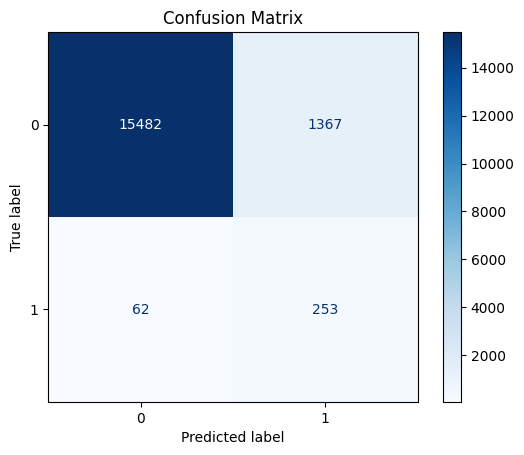

In [ ]:

# Standard Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# Logistic Regression Classifier
clf = LogisticRegression(
    random_state=42,
    class_weight="balanced",  # Handle class imbalance
)
clf.fit(X_train_scaled, y_train)

# Predictions
y_pred = clf.predict(X_valid_scaled)
y_pred_proba = clf.predict_proba(X_valid_scaled)[:, 1]

# Evaluation Metrics
f1 = f1_score(y_valid, y_pred)
roc_auc = roc_auc_score(y_valid, y_pred_proba)

print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC Score: {roc_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_valid, y_pred))

# Confusion Matrix
# Confusion Matrix Visualization
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred,
    display_labels=clf.classes_,
    cmap=plt.cm.Blues
)
plt.title("Confusion Matrix")
plt.show()


### FEATURE IMPORTANCE

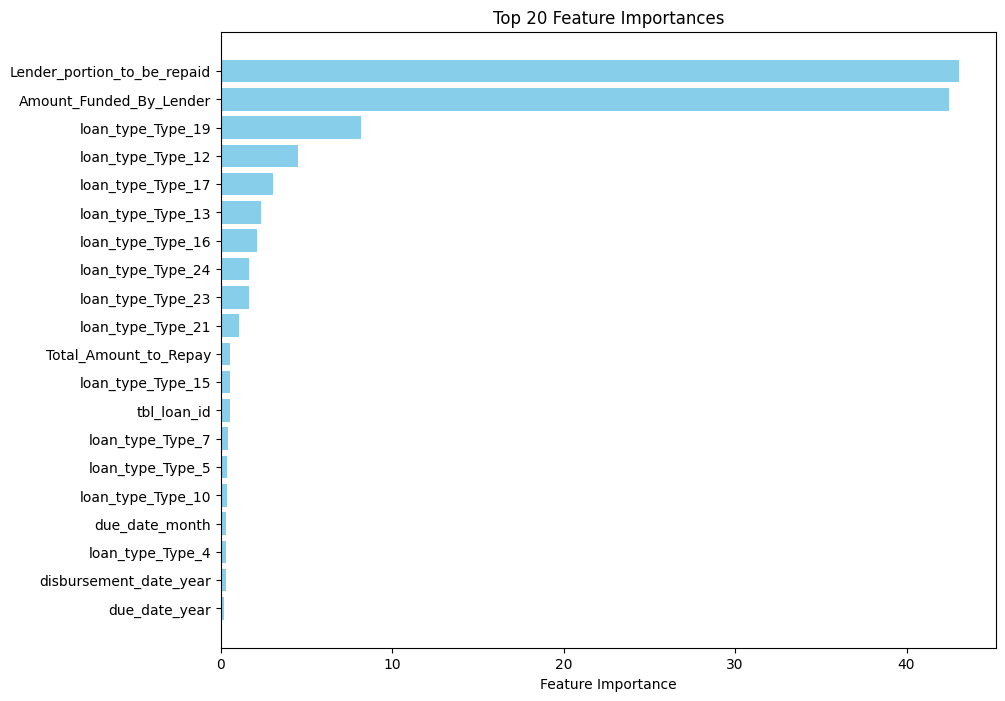

In [ ]:
# Feature Importance

# Get the absolute values of the coefficients
feature_importances = np.abs(clf.coef_).flatten()

# Create a DataFrame for feature importance
importance_df = pd.DataFrame({
    'Feature': features_for_modelling,
    'Importance': feature_importances
})

# Sort by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(20)

# Plot the top 20 feature importances
plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
plt.gca().invert_yaxis()  # To display the most important feature at the top
plt.xlabel('Feature Importance')
plt.title('Top 20 Feature Importances')
plt.show()

## Model Prediction & Inference

In [ ]:
# Make predictions on the test dataset
test_predictions = clf.predict(test_df[features_for_modelling])
test_predictions_proba = clf.predict_proba(test_df[features_for_modelling])[:, 1]

# Save the predictions to a CSV file

test_df['target'] = test_predictions
sub =  test_df[['ID', 'target']]
sub.head()


,ID,target
68654,ID_269404226088267278,0
68655,ID_255356300042267278,0
68656,ID_257026243764267278,0
68657,ID_264617299409267278,0
68658,ID_247613296713267278,0


In [ ]:
sub.to_csv('baseline_submission.csv', index=False)

#### To Do
* Handle imbalance
* Do more feature engineering
* Use more sophisticated machine learning algorithms
##### Good luck

train['target].value_counts()